# 03 · Modelagem clássica, validação e otimização

**Tarefa:** a partir dos 512 números do embedding FaRL, prever se a pessoa é **menor de 18 anos** (classe positiva = menor).

**Ordem do notebook (segue a especificação do projeto)**
1. Preparação dos dados
2. Baseline (Regressão Logística)
3. Comparação de 5 modelos (KNN, Árvore, Random Forest, AdaBoost, MLP)
4. Validação cruzada estratificada (estabilidade)
5. Leave-One-Out em amostra
6. Overfitting e underfitting (curvas de aprendizado e de validação)
7. Otimização de hiperparâmetros (Grid Search + Optuna)
8. Avaliação final no teste e no FG-NET + análise de viés
9. Salvamento

Tudo é registrado no **MLflow** (parâmetros, métricas, gráficos e modelos).

**Ponto de operação (igual ao artigo):** o limiar de decisão de cada modelo é ajustado **no `val`** para garantir recall de menores = 0,99
(no máximo 1% de "falso adulto") e depois aplicado, sem mudar, no `test` e no FG-NET.

Não precisa de GPU. Tempo total no Colab: ~30 a 45 min (a maior parte na seção 7).

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")
EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_URL = "https://github.com/Rodrigotorres1/veridade.git"
    if not os.path.exists("/content/repo"):
        os.system(f"git clone -q {REPO_URL} /content/repo")
    os.chdir("/content/repo"); os.system("git pull -q")
    os.makedirs("data/processed", exist_ok=True)
    os.system("cp /content/drive/MyDrive/projeto-ml/processed/features_farl.parquet data/processed/")
    os.system("pip install -q mlflow optuna")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import mlflow, mlflow.sklearn, optuna
from src.config import FEATURES_FILE, EMB_COLS, LIMIAR_PRINCIPAL, RECALL_ALVO, MLFLOW_EXPERIMENTOS, ROOT
from src.data.limpeza import carregar_base
from src.training.modelos import criar_modelo, espaco_busca, BASELINE, MODELOS
from src.training.avaliacao import (limiar_para_recall, metricas_binarias, plot_matriz_confusao,
                                    plot_curvas, taxa_falso_adulto_por_grupo)
from src.training.rastreio import configurar_mlflow, usar_experimento

FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
def salvar(nome):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{nome}.png", dpi=200, bbox_inches="tight"); plt.show()

print("MLflow:", configurar_mlflow())

Mounted at /content/drive
MLflow: sqlite:////content/repo/mlruns/mlflow.db


## 1. Preparação

In [2]:
df = carregar_base(FEATURES_FILE)   # já remove as duplicatas, como decidido na EDA
df["menor"] = (df["idade"] < LIMIAR_PRINCIPAL).astype(int)

partes = {s: df[df.split == s] for s in ["train", "val", "test", "test_externo"]}
X = {s: p[EMB_COLS].to_numpy(np.float32) for s, p in partes.items()}
y = {s: p["menor"].to_numpy() for s, p in partes.items()}
for s in X: print(f"{s:13s} {X[s].shape[0]:6d} imagens | {100 * y[s].mean():5.1f}% menores")

Duplicatas removidas: 389 | base final: 24299 imagens
train          16309 imagens |  18.0% menores
val             3498 imagens |  17.9% menores
test            3490 imagens |  18.0% menores
test_externo    1002 imagens |  63.9% menores


Funções de apoio: treinar, pontuar todos os splits, ajustar o limiar no `val` e registrar tudo no MLflow.
O **gap treino × validação** (diferença de PR-AUC) é registrado para diagnosticar overfitting.

In [3]:
def avaliar(modelo, nome, params, registrar_modelo=True, tags=None):
    t0 = time.time(); modelo.fit(X["train"], y["train"]); t_treino = time.time() - t0
    scores = {s: modelo.predict_proba(X[s])[:, 1] for s in X}
    limiar = limiar_para_recall(y["val"], scores["val"])
    m = {"limiar": limiar, "tempo_treino_s": t_treino}
    for s, pref in [("train", "treino_"), ("val", "val_"), ("test", "teste_"), ("test_externo", "fgnet_")]:
        m.update(metricas_binarias(y[s], scores[s], limiar, prefixo=pref))
    m["gap_pr_auc_treino_val"] = m["treino_pr_auc"] - m["val_pr_auc"]

    with mlflow.start_run(run_name=nome, nested=mlflow.active_run() is not None) as run:
        mlflow.set_tags({"modelo": nome, **(tags or {})})
        mlflow.log_params({k: str(v) for k, v in params.items()})
        mlflow.log_metrics(m)
        fig, ax = plt.subplots(1, 2, figsize=(8, 3.6))
        plot_matriz_confusao(y["val"], scores["val"], limiar, "Validação", ax[0])
        plot_matriz_confusao(y["test_externo"], scores["test_externo"], limiar, "FG-NET", ax[1])
        fig.suptitle(nome); plt.tight_layout(); mlflow.log_figure(fig, "matriz_confusao.png"); plt.close(fig)
        if registrar_modelo:
            mlflow.sklearn.log_model(modelo, name="modelo", serialization_format="cloudpickle")
    return {"modelo": nome, **m, "run_id": run.info.run_id}, scores, modelo

COLS = ["modelo", "val_f2", "val_precisao_menor", "val_pr_auc", "val_roc_auc", "teste_f2",
        "fgnet_f2", "fgnet_recall_menor", "gap_pr_auc_treino_val", "tempo_treino_s"]

## 2. Baseline: Regressão Logística

**Por que este baseline:** é o modelo linear mais simples para classificação binária, rápido, interpretável e com
`class_weight="balanced"` para lidar com o desbalanceamento. Como os embeddings do FaRL já organizam a idade (EDA, Fig. 6 e 8),
um modelo linear deve ir razoavelmente bem: qualquer modelo mais complexo precisa superá-lo para se justificar.

In [4]:
usar_experimento(MLFLOW_EXPERIMENTOS["baseline"])
res_base, scores_base, modelo_base = avaliar(criar_modelo(BASELINE), BASELINE, {"C": 1.0}, tags={"fase": "baseline"})
pd.DataFrame([res_base])[COLS].round(3)

2026/11/25 00:40:07 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/25 00:40:07 INFO mlflow.store.db.utils: Updating database tables
2026/11/25 00:40:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,modelo,val_f2,val_precisao_menor,val_pr_auc,val_roc_auc,teste_f2,fgnet_f2,fgnet_recall_menor,gap_pr_auc_treino_val,tempo_treino_s
0,Regressao Logistica,0.824,0.492,0.979,0.992,0.811,0.932,0.994,0.009,5.573


## 3. Comparação de modelos

**Métricas definidas antes de rodar:**
- **F2 no ponto de operação (recall = 0,99)**: métrica principal do artigo. Dá mais peso ao recall que à precisão
- **Precisão de menores** no mesmo ponto: quantos adultos são bloqueados à toa para garantir 99% dos menores barrados
- **PR-AUC e ROC-AUC**: qualidade da ordenação, independente do limiar (PR-AUC é mais informativa com classes desbalanceadas)
- **F2 no FG-NET**: generalização para outro domínio

Acurácia **não** é usada: um modelo que chama todos de adulto teria ~82% de acurácia (EDA, Fig. 2).

In [5]:
usar_experimento(MLFLOW_EXPERIMENTOS["comparacao"])
resultados, todos_scores, modelos_treinados = [res_base], {BASELINE: scores_base}, {BASELINE: modelo_base}
for nome in MODELOS:
    print(f"Treinando {nome}...", end=" ", flush=True)
    r, s, mod = avaliar(criar_modelo(nome), nome, {}, tags={"fase": "comparacao"})
    resultados.append(r); todos_scores[nome] = s; modelos_treinados[nome] = mod
    print(f"F2 val = {r['val_f2']:.3f} ({r['tempo_treino_s']:.0f}s)")

tabela = pd.DataFrame(resultados)[COLS].sort_values("val_f2", ascending=False).round(3)
tabela

Treinando KNN... 

2026/11/25 00:40:51 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


F2 val = 0.522 (0s)
Treinando Arvore de Decisao... 

2026/11/25 00:41:15 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


F2 val = 0.522 (20s)
Treinando Random Forest... 

2026/11/25 00:43:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


... (2 outputs left out)

F2 val = 0.723 (403s)
Treinando MLP... 

2026/11/25 00:50:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


F2 val = 0.847 (8s)


,modelo,val_f2,val_precisao_menor,val_pr_auc,val_roc_auc,teste_f2,fgnet_f2,fgnet_recall_menor,gap_pr_auc_treino_val,tempo_treino_s
5,MLP,0.847,0.537,0.982,0.993,0.849,0.932,0.994,0.014,8.277
3,Random Forest,0.836,0.516,0.981,0.992,0.838,0.919,1.000,0.019,150.510
0,Regressao Logistica,0.824,0.492,0.979,0.992,0.811,0.932,0.994,0.009,5.573
4,AdaBoost,0.723,0.348,0.974,0.988,0.721,0.908,0.998,0.010,402.927
1,KNN,0.522,0.179,0.976,0.988,0.523,0.898,1.000,0.024,0.053
2,Arvore de Decisao,0.522,0.179,0.838,0.915,0.523,0.898,1.000,0.130,20.091


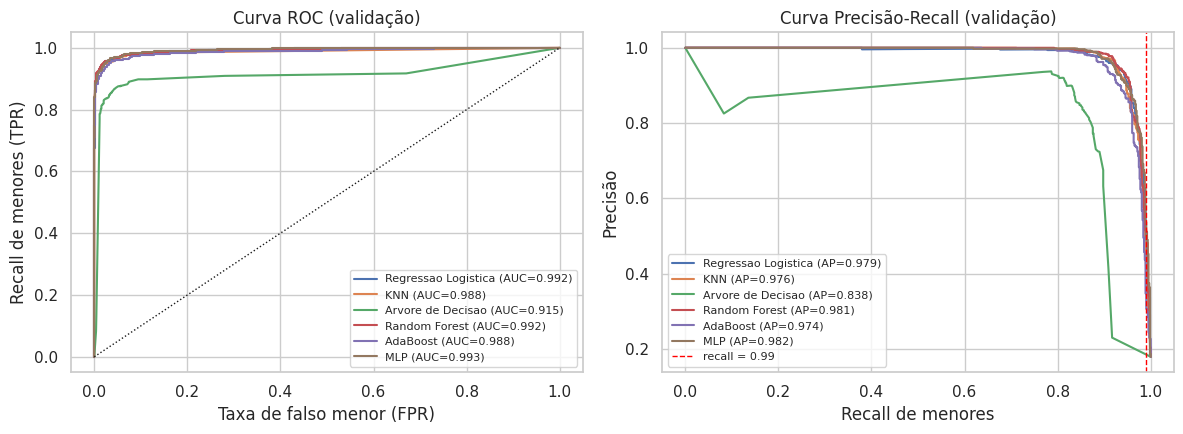

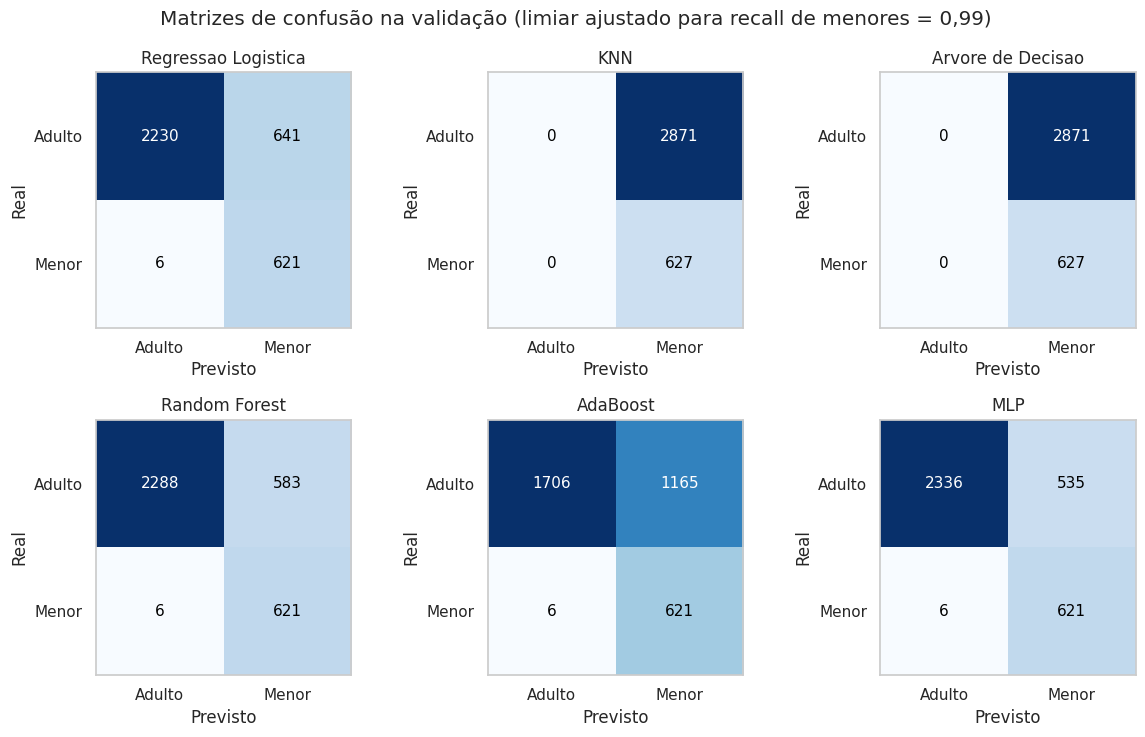

In [6]:
fig = plot_curvas({n: s["val"] for n, s in todos_scores.items()}, y["val"], "(validação)")
salvar("fig9_roc_pr_comparacao")

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, r in zip(axes.ravel(), resultados):
    plot_matriz_confusao(y["val"], todos_scores[r["modelo"]]["val"], r["limiar"], r["modelo"], ax)
plt.suptitle("Matrizes de confusão na validação (limiar ajustado para recall de menores = 0,99)")
salvar("fig10_matrizes_confusao")

**Interpretação:** O MLP foi o melhor modelo no ponto de operação (F2 = 0,847 e precisão de 53,7% na validação), seguido pelo Random Forest (0,836) e pela Regressão Logística (0,824). Apesar de quase todos terem PR-AUC entre 0,974 e 0,982, o F2 no ponto de operação varia muito (de 0,52 a 0,85): a diferença entre os modelos aparece no extremo da curva, onde é preciso barrar 99% dos menores. KNN e Árvore de Decisão tiveram limiar 0 porque produzem probabilidades em degraus (vários menores recebem probabilidade exatamente 0); para atingir o recall de 0,99, o limiar precisou ir a zero e todos passaram a ser classificados como menores (precisão de 17,9%, igual à proporção de menores). Isso mostra que, em pontos de operação rígidos, não basta ordenar bem: o modelo precisa produzir probabilidades finas na cauda da distribuição. No FG-NET o F2 é mais alto para todos (0,90 a 0,94), mas isso não indica melhor generalização: 64% das imagens do FG-NET são de menores, o que eleva a precisão naturalmente.

## 4. Validação cruzada estratificada (5 folds) no treino

**Por que estratificada:** com só ~18% de menores, um fold aleatório poderia ficar com proporção bem diferente.
A estratificação mantém a mesma proporção em todos os folds. O **desvio padrão** entre folds mede a **estabilidade** de cada modelo.

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, fbeta_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas_cv = {"pr_auc": "average_precision", "roc_auc": "roc_auc",
               "f2_limiar_05": make_scorer(fbeta_score, beta=2)}
cv_linhas = []
for nome in [BASELINE] + MODELOS:
    print(f"CV {nome}...", end=" ", flush=True)
    cv = cross_validate(criar_modelo(nome), X["train"], y["train"], cv=skf, scoring=metricas_cv,
                        return_train_score=True, n_jobs=1)
    for k in range(5):
        cv_linhas.append({"modelo": nome, "fold": k, **{m: cv[f"test_{m}"][k] for m in metricas_cv},
                          "pr_auc_treino": cv["train_pr_auc"][k]})
    print(f"PR-AUC = {cv['test_pr_auc'].mean():.3f} ± {cv['test_pr_auc'].std():.3f}")

cv_df = pd.DataFrame(cv_linhas)
resumo_cv = cv_df.groupby("modelo").agg(["mean", "std"]).drop(columns="fold").round(3)
resumo_cv

CV Regressao Logistica... PR-AUC = 0.975 ± 0.005
CV KNN... PR-AUC = 0.974 ± 0.007
CV Arvore de Decisao... PR-AUC = 0.826 ± 0.007
CV Random Forest... PR-AUC = 0.978 ± 0.004
CV AdaBoost... PR-AUC = 0.971 ± 0.005
CV MLP... PR-AUC = 0.978 ± 0.006


pr_auc        roc_auc        f2_limiar_05         \
                      mean    std    mean    std         mean    std   
modelo                                                                 
AdaBoost             0.971  0.005   0.988  0.004        0.912  0.014   
Arvore de Decisao    0.826  0.008   0.905  0.007        0.837  0.012   
KNN                  0.974  0.008   0.988  0.004        0.914  0.015   
MLP                  0.978  0.007   0.991  0.004        0.928  0.018   
Random Forest        0.978  0.005   0.991  0.003        0.882  0.014   
Regressao Logistica  0.975  0.006   0.991  0.003        0.933  0.012   

                    pr_auc_treino         
                             mean    std  
modelo                                    
AdaBoost                    0.986  0.001  
Arvore de Decisao           0.968  0.006  
KNN                         1.000  0.000  
MLP                         0.994  0.005  
Random Forest               1.000  0.000  
Regressao Logistica         0.989  0.001

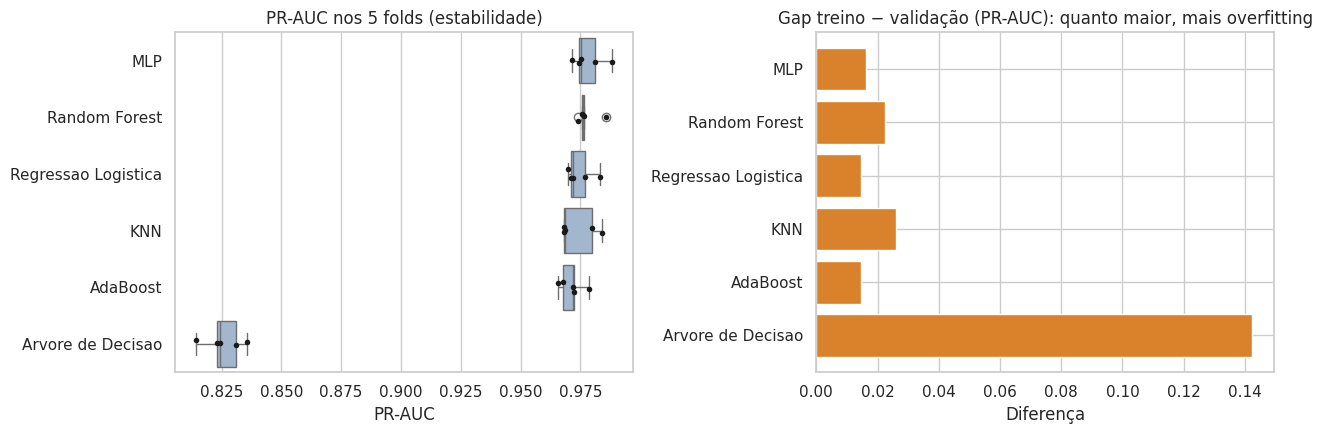

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ordem = cv_df.groupby("modelo")["pr_auc"].mean().sort_values(ascending=False).index
sns.boxplot(cv_df, x="pr_auc", y="modelo", order=ordem, ax=axes[0], color="#9BB7D4")
sns.stripplot(cv_df, x="pr_auc", y="modelo", order=ordem, ax=axes[0], color="k", size=4)
axes[0].set(title="PR-AUC nos 5 folds (estabilidade)", xlabel="PR-AUC", ylabel="")
gap = cv_df.assign(gap=cv_df.pr_auc_treino - cv_df.pr_auc).groupby("modelo")["gap"].mean().loc[ordem]
axes[1].barh(gap.index, gap.values, color="#D9822B"); axes[1].invert_yaxis()
axes[1].set(title="Gap treino − validação (PR-AUC): quanto maior, mais overfitting", xlabel="Diferença")
salvar("fig11_validacao_cruzada")

with mlflow.start_run(run_name="validacao_cruzada_5fold"):
    mlflow.set_tag("fase", "validacao_cruzada")
    for nome, g in cv_df.groupby("modelo"):
        chave = nome.replace(" ", "_")
        mlflow.log_metrics({f"{chave}_pr_auc_media": g.pr_auc.mean(), f"{chave}_pr_auc_desvio": g.pr_auc.std(),
                            f"{chave}_gap": (g.pr_auc_treino - g.pr_auc).mean()})
    mlflow.log_figure(fig, "validacao_cruzada.png")

**Interpretação:** Com exceção da Árvore de Decisão, todos os modelos tiveram PR-AUC entre 0,971 e 0,978, com desvio padrão de no máximo 0,008 entre os folds: os resultados são estáveis e não dependem do split. As diferenças entre os melhores (MLP 0,978 ± 0,007; Random Forest 0,978 ± 0,005; Regressão Logística 0,975 ± 0,006; KNN 0,974 ± 0,008) são menores que o próprio desvio, ou seja, na qualidade de ordenação eles são praticamente equivalentes; o que os separa é o comportamento no ponto de operação (seção 3). A Árvore de Decisão é o único caso claro de overfitting: PR-AUC de 0,968 no treino contra 0,826 na validação (gap de 0,142). KNN e Random Forest chegam a PR-AUC de praticamente 1,0 no treino, mas por construção (o KNN com pesos por distância "reconhece" cada ponto de treino como seu próprio vizinho, e cada árvore da floresta memoriza sua amostra), então o gap deles (0,026 e 0,022) é pequeno quando comparado com a validação.

## 5. Leave-One-Out (em amostra)

**Por que só numa amostra:** o LOO treina um modelo para cada exemplo. Com ~16 mil imagens de treino seriam 16 mil treinos por modelo,
o que é inviável e desnecessário (com tanta amostra, o k-fold já tem variância baixa). Para mostrar o método e comparar com o k-fold,
rodamos LOO em uma **amostra estratificada de 400 imagens** com os dois modelos mais rápidos.

In [9]:
from sklearn.model_selection import LeaveOneOut, cross_val_predict, train_test_split
from sklearn.metrics import average_precision_score

idx, _ = train_test_split(np.arange(len(y["train"])), train_size=400, stratify=y["train"], random_state=42)
Xa, ya = X["train"][idx], y["train"][idx]
loo_linhas = []
for nome in [BASELINE, "KNN"]:
    for metodo, cv in [("LOO (400 treinos)", LeaveOneOut()), ("5-fold", StratifiedKFold(5, shuffle=True, random_state=42))]:
        t0 = time.time()
        s = cross_val_predict(criar_modelo(nome), Xa, ya, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
        loo_linhas.append({"modelo": nome, "método": metodo, "pr_auc": average_precision_score(ya, s),
                           "tempo_s": time.time() - t0})
loo_df = pd.DataFrame(loo_linhas).round(3)
with mlflow.start_run(run_name="leave_one_out_amostra"):
    mlflow.set_tag("fase", "loo")
    for r in loo_linhas:
        mlflow.log_metric(f"{r['modelo'].replace(' ', '_')}_{'loo' if 'LOO' in r['método'] else 'kfold'}_pr_auc", r["pr_auc"])
loo_df

,modelo,método,pr_auc,tempo_s
0,Regressao Logistica,LOO (400 treinos),0.960,8.924
1,Regressao Logistica,5-fold,0.964,0.080
2,KNN,LOO (400 treinos),0.962,1.335
3,KNN,5-fold,0.963,0.037


**Interpretação:** Na amostra de 400 imagens, LOO e 5-fold deram PR-AUC praticamente iguais: 0,960 contra 0,964 na Regressão Logística e 0,962 contra 0,963 no KNN (diferenças de no máximo 0,004). Já o custo é muito diferente: o LOO levou 8,9 s contra 0,08 s na Regressão Logística (cerca de 110 vezes mais) e 1,3 s contra 0,04 s no KNN. Como o LOO não trouxe nenhuma informação adicional e seu custo cresce com o tamanho da base (no treino completo seriam cerca de 16 mil treinos por modelo), o k-fold estratificado é a estratégia adequada para este problema. A PR-AUC menor que a do treino completo (cerca de 0,96 contra 0,97) é esperada, já que os modelos foram treinados com só 400 imagens.

## 6. Overfitting e underfitting

- **Curva de aprendizado** (melhor modelo): se treino e validação convergem, mais dados ajudariam pouco; se há distância grande, há overfitting.
- **Curva de validação** (Árvore de Decisão, variando `max_depth`): mostra a transição de underfitting (árvore rasa) para overfitting (árvore profunda).

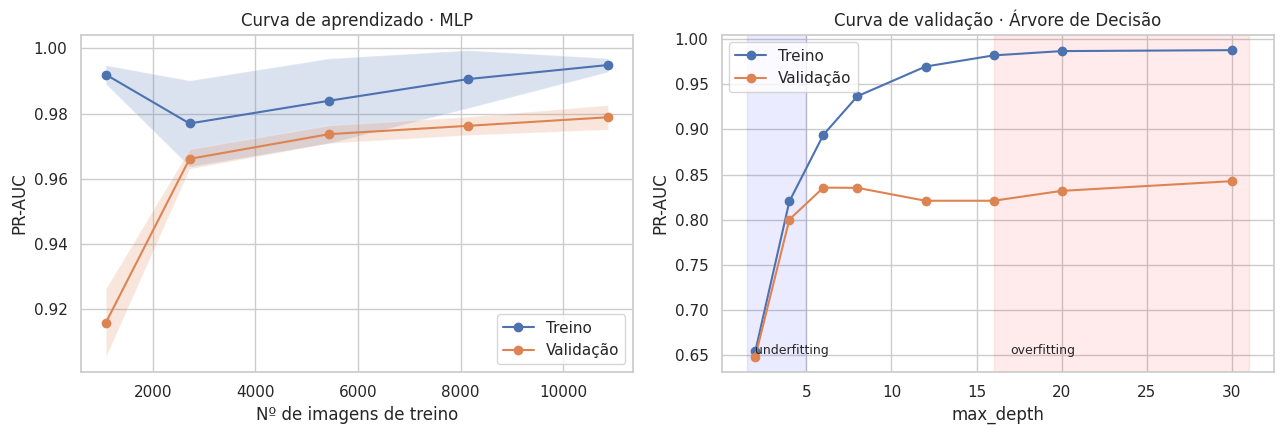

In [10]:
from sklearn.model_selection import learning_curve, validation_curve

melhor_inicial = tabela.iloc[0]["modelo"]
tam, tr_sc, va_sc = learning_curve(criar_modelo(melhor_inicial), X["train"], y["train"],
                                   train_sizes=[.1, .25, .5, .75, 1.0], cv=StratifiedKFold(3, shuffle=True, random_state=42),
                                   scoring="average_precision", n_jobs=-1)
profs = [2, 4, 6, 8, 12, 16, 20, 30]
vtr, vva = validation_curve(criar_modelo("Arvore de Decisao"), X["train"], y["train"], param_name="modelo__max_depth",
                            param_range=profs, cv=StratifiedKFold(3, shuffle=True, random_state=42),
                            scoring="average_precision", n_jobs=-1)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
for sc, rot in [(tr_sc, "Treino"), (va_sc, "Validação")]:
    a1.plot(tam, sc.mean(1), marker="o", label=rot); a1.fill_between(tam, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), alpha=.2)
a1.set(title=f"Curva de aprendizado · {melhor_inicial}", xlabel="Nº de imagens de treino", ylabel="PR-AUC"); a1.legend()
for sc, rot in [(vtr, "Treino"), (vva, "Validação")]:
    a2.plot(profs, sc.mean(1), marker="o", label=rot)
a2.axvspan(1.5, 5, alpha=.08, color="blue"); a2.text(2, a2.get_ylim()[0] + .02, "underfitting", fontsize=9)
a2.axvspan(16, 31, alpha=.08, color="red"); a2.text(17, a2.get_ylim()[0] + .02, "overfitting", fontsize=9)
a2.set(title="Curva de validação · Árvore de Decisão", xlabel="max_depth", ylabel="PR-AUC"); a2.legend()
salvar("fig12_overfitting")

**Interpretação:** Na curva de aprendizado do MLP, a PR-AUC de validação sobe de 0,916 (cerca de 1.000 imagens) para 0,979 (cerca de 11.000), e a distância para o treino cai até cerca de 0,016. O modelo não está em overfitting relevante, e a curva de validação ainda sobe levemente no final, indicando que mais dados de treino trariam ganhos pequenos. A curva de validação da Árvore mostra os dois extremos: com profundidade 2, treino e validação ficam em 0,65 (underfitting, o modelo é simples demais); a validação atinge o máximo de cerca de 0,836 com profundidade 6 a 8 e depois estabiliza, enquanto o treino continua subindo até 0,99 (overfitting, a árvore passa a decorar o treino).

## 7. Otimização de hiperparâmetros

**Estratégia (justificativa):**
- **Grid Search** no KNN: tem poucos hiperparâmetros discretos, então dá para testar todas as combinações com validação cruzada de 3 folds.
- **Optuna (TPE)** nos 2 melhores modelos da comparação: espaços maiores e contínuos, onde testar tudo é caro. O Optuna aprende com as
  tentativas anteriores e concentra a busca nas regiões promissoras, encontrando bons valores com menos treinos que o Random Search.
- Critério de otimização: **PR-AUC na validação** (resume a qualidade em todos os limiares; o limiar de operação é ajustado depois).
- Cada tentativa vira um run filho no MLflow, para documentar todos os parâmetros avaliados.

In [11]:
from sklearn.model_selection import GridSearchCV
usar_experimento(MLFLOW_EXPERIMENTOS["tuning"])

grade = {"modelo__n_neighbors": [5, 15, 25, 50, 75], "modelo__weights": ["uniform", "distance"]}
t0 = time.time()
gs = GridSearchCV(criar_modelo("KNN"), grade, scoring="average_precision",
                  cv=StratifiedKFold(3, shuffle=True, random_state=42), n_jobs=-1).fit(X["train"], y["train"])
print(f"Grid Search KNN: {len(gs.cv_results_['params'])} combinações em {time.time() - t0:.0f}s | melhor: {gs.best_params_} | PR-AUC CV = {gs.best_score_:.3f}")
with mlflow.start_run(run_name="grid_search_KNN"):
    mlflow.set_tag("fase", "tuning"); mlflow.set_tag("estrategia", "grid_search")
    mlflow.log_params({k: str(v) for k, v in gs.best_params_.items()}); mlflow.log_metric("cv_pr_auc", gs.best_score_)
    pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score"]].to_csv("/tmp/grid_knn.csv", index=False)
    mlflow.log_artifact("/tmp/grid_knn.csv")

Grid Search KNN: 10 combinações em 78s | melhor: {'modelo__n_neighbors': 75, 'modelo__weights': 'distance'} | PR-AUC CV = 0.978


In [12]:
from sklearn.metrics import average_precision_score
optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TENTATIVAS = 25          # máximo de tentativas por modelo
LIMITE_MIN = 12            # ...ou até 12 minutos por modelo, o que vier primeiro
candidatos = [m for m in tabela["modelo"] if m != BASELINE][:2]
print("Otimizando:", candidatos)

estudos = {}
for nome in candidatos:
    def objetivo(trial, nome=nome):
        params = espaco_busca(trial, nome)
        mod = criar_modelo(nome, **params).fit(X["train"], y["train"])
        ap = average_precision_score(y["val"], mod.predict_proba(X["val"])[:, 1])
        with mlflow.start_run(run_name=f"{nome}_trial_{trial.number}", nested=True):
            mlflow.log_params({k: str(v) for k, v in params.items()}); mlflow.log_metric("val_pr_auc", ap)
        return ap
    with mlflow.start_run(run_name=f"optuna_{nome}"):
        mlflow.set_tags({"fase": "tuning", "estrategia": "optuna_tpe", "modelo": nome})
        estudo = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
        t0 = time.time(); estudo.optimize(objetivo, n_trials=N_TENTATIVAS, timeout=LIMITE_MIN * 60, show_progress_bar=True)
        mlflow.log_params({f"melhor_{k}": str(v) for k, v in estudo.best_params.items()})
        mlflow.log_metric("melhor_val_pr_auc", estudo.best_value)
        estudos[nome] = estudo
    print(f"{nome}: melhor PR-AUC val = {estudo.best_value:.3f} em {time.time() - t0:.0f}s | {estudo.best_params}")

Otimizando: ['MLP', 'Random Forest']


  0%|          | 0/25 [00:00<?, ?it/s]

MLP: melhor PR-AUC val = 0.985 em 423s | {'camadas': '512-256', 'alpha': 2.0647718672240873e-05, 'learning_rate_init': 0.0019670088959263697}


  0%|          | 0/25 [00:00<?, ?it/s]

Random Forest: melhor PR-AUC val = 0.976 em 994s | {'n_estimators': 250, 'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 7}


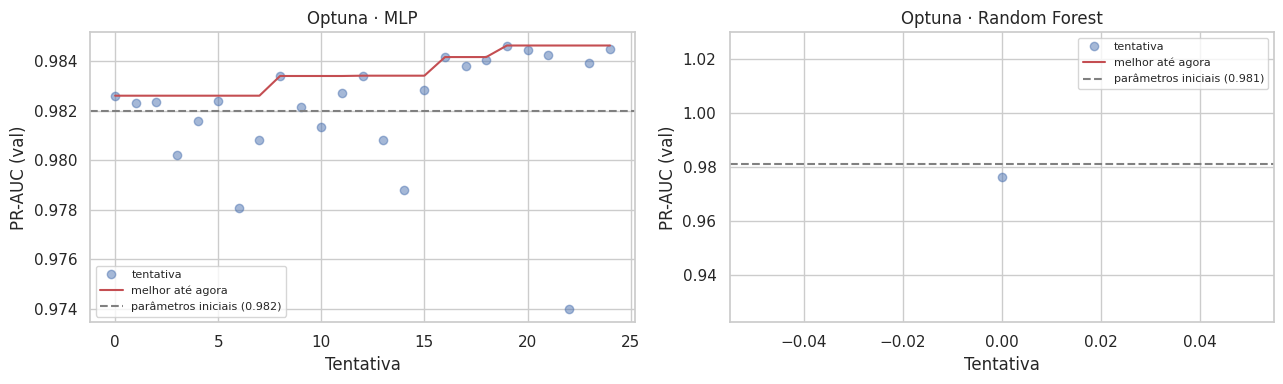

In [13]:
fig, axes = plt.subplots(1, len(estudos), figsize=(6.5 * len(estudos), 4), squeeze=False)
for ax, (nome, est) in zip(axes[0], estudos.items()):
    v = [t.value for t in est.trials]
    ax.plot(v, "o", alpha=.5, label="tentativa"); ax.plot(np.maximum.accumulate(v), "r-", label="melhor até agora")
    base = tabela.set_index("modelo").loc[nome, "val_pr_auc"]
    ax.axhline(base, ls="--", c="gray", label=f"parâmetros iniciais ({base:.3f})")
    ax.set(title=f"Optuna · {nome}", xlabel="Tentativa", ylabel="PR-AUC (val)"); ax.legend(fontsize=8)
salvar("fig13_optuna")

**Interpretação:** No MLP, o Optuna rodou as 25 tentativas e melhorou a PR-AUC de validação de 0,982 (parâmetros iniciais) para 0,985; a melhora apareceu de forma mais clara no ponto de operação, com o F2 subindo de 0,847 para 0,892 e a precisão de 53,7% para 63,9%. O melhor valor surgiu na tentativa 19 e a curva estabilizou depois disso, indicando que mais tentativas trariam pouco ganho. No Random Forest, cada treino levou cerca de 16 minutos (configurações com muitas árvores e max_features = 0,3), então o limite de 12 minutos permitiu uma única tentativa, que ficou abaixo dos parâmetros iniciais (0,976 contra 0,981). É um resultado negativo explicado pelo orçamento computacional: com o tempo disponível, a busca não chegou a explorar o espaço. Para modelos caros, seria necessário restringir o espaço de busca (por exemplo, max_features = "sqrt") ou usar uma amostra do treino durante a busca.

## 8. Avaliação final

Os modelos otimizados são retreinados com os melhores parâmetros, e o vencedor é escolhido **pelo F2 na validação**.
O teste e o FG-NET só são olhados agora, uma única vez.

In [14]:
usar_experimento(MLFLOW_EXPERIMENTOS["comparacao"])
finais = []
for nome, est in estudos.items():
    r, s, mod = avaliar(criar_modelo(nome, **est.best_params), f"{nome} (otimizado)", est.best_params,
                        tags={"fase": "final_otimizado"})
    finais.append(r); todos_scores[f"{nome} (otimizado)"] = s; modelos_treinados[f"{nome} (otimizado)"] = mod
r, s, mod = avaliar(gs.best_estimator_, "KNN (grid search)", gs.best_params_, tags={"fase": "final_otimizado"})
finais.append(r); todos_scores["KNN (grid search)"] = s; modelos_treinados["KNN (grid search)"] = mod

tabela_final = pd.DataFrame(resultados + finais)[COLS + ["limiar", "teste_recall_menor", "teste_precisao_menor", "teste_taxa_falso_adulto", "run_id"]]
tabela_final = tabela_final.sort_values("val_f2", ascending=False).reset_index(drop=True)
VENCEDOR = tabela_final.loc[0, "modelo"]
print("Modelo vencedor (maior F2 na validação):", VENCEDOR)
tabela_final.drop(columns="run_id").round(3)

2026/11/25 02:01:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/25 02:17:51 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/25 02:18:14 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mec

Modelo vencedor (maior F2 na validação): MLP (otimizado)


,modelo,val_f2,val_precisao_menor,val_pr_auc,val_roc_auc,teste_f2,fgnet_f2,fgnet_recall_menor,gap_pr_auc_treino_val,tempo_treino_s,limiar,teste_recall_menor,teste_precisao_menor,teste_taxa_falso_adulto
0,MLP (otimizado),0.892,0.639,0.985,0.994,0.889,0.941,0.995,0.008,19.360,0.017,0.987,0.635,0.013
1,MLP,0.847,0.537,0.982,0.993,0.849,0.932,0.994,0.014,8.277,0.009,0.990,0.539,0.010
2,Random Forest,0.836,0.516,0.981,0.992,0.838,0.919,1.000,0.019,150.510,0.069,0.987,0.522,0.013
3,Regressao Logistica,0.824,0.492,0.979,0.992,0.811,0.932,0.994,0.009,5.573,0.016,0.986,0.475,0.014
4,KNN (grid search),0.778,0.419,0.979,0.990,0.778,0.918,1.000,0.021,0.035,0.013,0.995,0.415,0.005
5,Random Forest (otimizado),0.742,0.370,0.976,0.988,0.741,0.913,1.000,0.023,986.726,0.053,0.997,0.366,0.003
6,AdaBoost,0.723,0.348,0.974,0.988,0.721,0.908,0.998,0.010,402.927,0.354,0.994,0.343,0.006
7,KNN,0.522,0.179,0.976,0.988,0.523,0.898,1.000,0.024,0.053,0.000,1.000,0.180,0.000
8,Arvore de Decisao,0.522,0.179,0.838,0.915,0.523,0.898,1.000,0.130,20.091,0.000,1.000,0.180,0.000


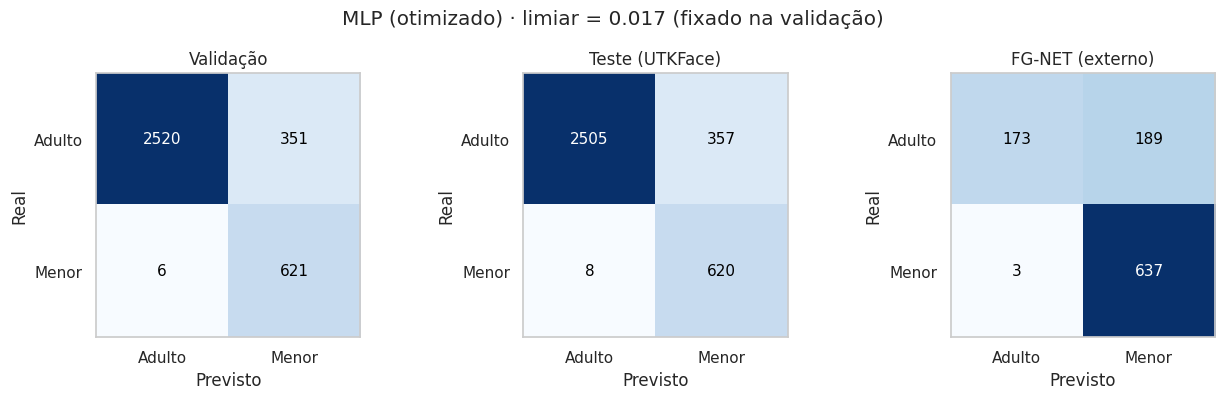

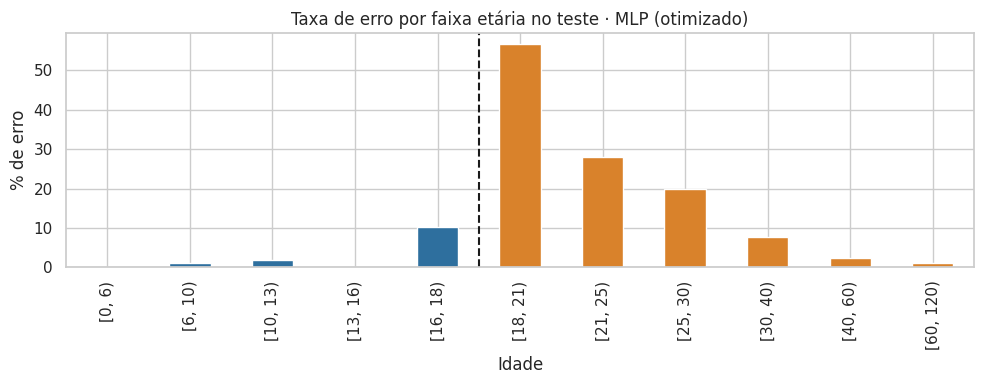

In [15]:
sv = todos_scores[VENCEDOR]; lim = tabela_final.loc[0, "limiar"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (s, t) in zip(axes, [("val", "Validação"), ("test", "Teste (UTKFace)"), ("test_externo", "FG-NET (externo)")]):
    plot_matriz_confusao(y[s], sv[s], lim, t, ax)
plt.suptitle(f"{VENCEDOR} · limiar = {lim:.3f} (fixado na validação)"); salvar("fig14_vencedor_matrizes")

# Erro por idade: onde o modelo erra? (esperado: perto dos 18 anos)
p = partes["test"].assign(prob=sv["test"], erro=lambda d: (d.prob >= lim).astype(int) != d.menor)
taxa = p.groupby(pd.cut(p.idade, [0, 6, 10, 13, 16, 18, 21, 25, 30, 40, 60, 120], right=False), observed=True)["erro"].mean() * 100
ax = taxa.plot.bar(figsize=(10, 4), color=["#2E6F9E" if i.right <= 18 else "#D9822B" for i in taxa.index])
ax.set(title=f"Taxa de erro por faixa etária no teste · {VENCEDOR}", xlabel="Idade", ylabel="% de erro")
ax.axvline(4.5, ls="--", c="k"); salvar("fig15_erro_por_idade")

**Interpretação:** O MLP otimizado foi o vencedor. Com o limiar fixado na validação (0,017), o teste confirmou o comportamento esperado: 620 de 628 menores foram barrados (taxa de falso adulto de 1,27%, próxima da meta de 1%; a pequena diferença é esperada porque o limiar foi ajustado em outro conjunto). O custo dessa segurança é que 357 de 2.862 adultos (12,5%) seriam bloqueados indevidamente e encaminhados para verificação adicional. No FG-NET, só 3 de 640 menores passaram como adultos (0,47%), mas 189 de 362 adultos (52%) foram classificados como menores: os adultos do FG-NET são majoritariamente jovens, justamente a faixa mais confundida.

**Interpretação:** Os erros estão concentrados ao redor do limiar de 18 anos. Entre os menores, praticamente todos os erros (falsos adultos) vêm da faixa de 16 a 18 anos (cerca de 10% de erro), enquanto crianças de 0 a 6 e adolescentes de 13 a 16 não tiveram erros. Entre os adultos, a taxa de erro é de cerca de 57% para quem tem 18 a 21 anos, 28% de 21 a 25 e 20% de 25 a 30, caindo para menos de 3% acima dos 40. Na prática, o modelo é muito seguro para identificar crianças e adultos mais velhos, e a incerteza fica em uma faixa estreita perto do limiar, onde até humanos teriam dificuldade de estimar a idade por uma foto. Essa é a motivação do artigo para as cabeças binárias por limiar, que testaremos na reprodução.

### Viés: taxa de falso adulto por grupo racial (teste UTKFace)
Mesmo com o limiar global garantindo ~1% de falso adulto, a taxa pode ser diferente entre grupos (EDA, Fig. 5).

In [16]:
raca = partes["test"]["raca"].map({0: "Branca", 1: "Negra", 2: "Asiática", 3: "Indiana", 4: "Outras"}).to_numpy()
vies = pd.DataFrame(taxa_falso_adulto_por_grupo(y["test"], sv["test"], lim, raca)).T
vies["taxa_falso_adulto_%"] = (vies["taxa_falso_adulto"] * 100).round(2)
with mlflow.start_run(run_id=tabela_final.loc[0, "run_id"]):
    mlflow.log_metrics({f"vies_falso_adulto_{g}": v for g, v in vies["taxa_falso_adulto"].items()})
    mlflow.set_tag("vencedor", "sim")
vies[["n_menores", "taxa_falso_adulto_%"]]

,n_menores,taxa_falso_adulto_%
Asiática,139.0,0.00
Branca,269.0,1.12
Indiana,102.0,2.94
Negra,46.0,4.35
Outras,72.0,0.00


**Interpretação:** A taxa de falso adulto não é igual entre os grupos: 0% para asiáticos (0 de 139 menores) e "outras" (0 de 72), 1,12% para brancos (3 de 269), 2,94% para indianos (3 de 102) e 4,35% para negros (2 de 46). O grupo negro tem a maior taxa, cerca de 4 vezes a média geral de 1,27%, o que é coerente com a EDA: menores negros são cerca de 1% do dataset, então o modelo viu poucos exemplos desse grupo. Porém, as amostras são pequenas e os intervalos de confiança de 95% (Wilson) se sobrepõem bastante: negra de 1,2% a 14,5%, indiana de 1,0% a 8,3%, branca de 0,4% a 3,2% e asiática de 0% a 2,7%. Ou seja, há um sinal de viés que não pode ser descartado, mas o teste não tem tamanho suficiente para confirmá-lo estatisticamente. Num sistema real de verificação de idade, isso exigiria uma avaliação com mais menores de cada grupo e, se confirmado, limiares por grupo ou mais dados de treino dos grupos sub-representados.

## 9. Salvamento

In [17]:
uri = f"runs:/{tabela_final.loc[0, 'run_id']}/modelo"
mlflow.register_model(uri, "veridade-classico")
tabela_final.to_csv(ROOT / "reports" / "resultados_modelos_classicos.csv", index=False)
cv_df.to_csv(ROOT / "reports" / "validacao_cruzada.csv", index=False)
print("Modelo registrado como 'veridade-classico' e tabelas salvas em reports/")

if EM_COLAB:
    os.system("mkdir -p /content/drive/MyDrive/projeto-ml/resultados && "
              "cp -r reports/figures reports/*.csv mlruns /content/drive/MyDrive/projeto-ml/resultados/")
    print("Figuras, tabelas e MLflow copiados para MyDrive/projeto-ml/resultados/")

Successfully registered model 'veridade-classico'.
2026/11/25 02:18:19 WARNING mlflow.tracking._model_registry.fluent: Run with id 8ca5995c99454a63aa4433317b83ea48 has no artifacts at artifact path 'modelo', registering model based on models:/m-3214183ca5414977b309443bb4051c7e instead
Created version '1' of model 'veridade-classico'.


Modelo registrado como 'veridade-classico' e tabelas salvas em reports/
Figuras, tabelas e MLflow copiados para MyDrive/projeto-ml/resultados/


**Para ver o MLflow com interface gráfica (opcional, no Colab):** rode numa célula
`!pip install -q pyngrok` e siga a documentação do ngrok. É mais simples ver localmente: baixe a pasta `mlruns` do Drive para o repositório
e rode `mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db` no terminal. Na Fase 4 o MLflow sobe no Docker.